### Comparison between SteadierCom and experimental results

In [47]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt

import sys

sys.path.append("../functions/")
import general

import compare_met_exp_sim.correlation as correlation
import compare_met_exp_sim.diagnostic as diagnostic
import compare_met_exp_sim.venturelli2018 as venturelli2018
import compare_met_exp_sim.general_funcs as general_funcs

In [48]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [49]:
smetana =  pd.read_csv("../output/Guillen2021/smetana/_detailed.tsv",sep="\t")

#### Mapping names to seed ids (seem to have a good overlap)

In [50]:
with open("../data/Venturelli2018/generated/metid2metname.json") as file:
    metid2metname = json.load(file)
    
with open("../data/Venturelli2018/generated/metname2metanetx.json") as file:
    metname2metanetx = json.load(file)
    
with open("../data/Venturelli2018/generated/metname_groups.json") as file:
    metname_groups = json.load(file)

with open("../data/Venturelli2018/generated/metname2group.json") as file:
    metname2group = json.load(file)

with open("../data/Venturelli2018/generated/metid2group.json") as file:
    metid2group = json.load(file)

In [51]:
len(set(metname2metanetx.keys())-set(metid2metname.values()))

33

**Metabolomics**

In [52]:
raw_data_exp,signal_exp,met_groups_model,metnames_not_included = venturelli2018.load_experimental_results()

INFO     | load_experimental_results_venturelli loads and processes metabolomics data from Venturelli et al. 2018 (Dataset EV4) in
	 ../data/Venturelli2018/msb178157-sup-0005-datasetev4.xlsx

	 Results are filtered by metabolites present in models.
INFO     | _assign_groups_and_filter_by_models assigns metabolite groups to the metabolites 
 and filters out metabolites that do not exist in any model.
INFO     | Loading models from Venturelli et al (2018)...


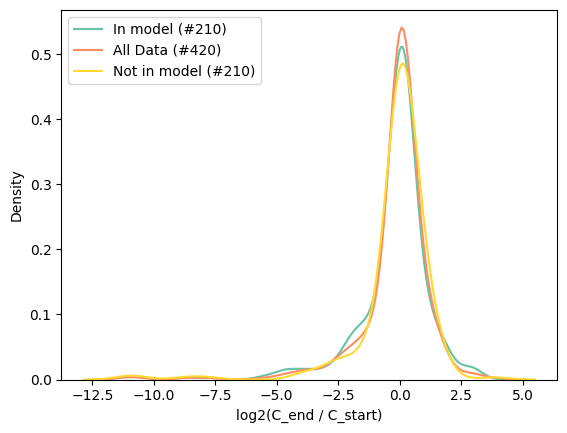

In [53]:
import seaborn as sns

df = signal_exp[list(met_groups_model)]
df_not = signal_exp[~signal_exp.index.isin(list(met_groups_model))]
fig, ax = plt.subplots(1,1)

palette = sns.color_palette("Set2")
sns.kdeplot(df, ax=ax, color=palette[0], label=f"In model (#{df.shape[0]})")
sns.kdeplot(signal_exp, ax=ax, color=palette[1], label=f"All Data (#{signal_exp.shape[0]})")
sns.kdeplot(df_not, ax=ax, color=palette[5], label=f"Not in model (#{df_not.shape[0]})")
ax.set_xlabel("log2(C_end / C_start)")
ax.legend()

**Load steadiercom results**

In [54]:
simulation_dict = venturelli2018.load_simulation_results(metid2group,all_communities=False)

INFO     | load_simulation_results loads simulation results from 
	../output/Venturelli2018/results_steadiercom, 
	../output/Venturelli2018/steadycom and 
	../output/Venturelli2018/smetana
 Only loads results for community 'NONE' (full community)
INFO     | _prepare_sim_met_venturelli removes environment from receivers and all compounds that are not found in metabolomics and map to AGORA identifiers
INFO     | _prepare_sim_met_venturelli removes environment from receivers and all compounds that are not found in metabolomics and map to AGORA identifiers
INFO     | _prepare_sim_met_venturelli removes environment from receivers and all compounds that are not found in metabolomics and map to AGORA identifiers
INFO     | _prepare_sim_met_venturelli removes environment from donors and all compounds that are not found in metabolomics and map to AGORA identifiers
INFO     | _prepare_sim_met_venturelli removes environment from donors and all compounds that are not found in metabolomics and map 

## Correlation analysis - continuous data 


**Motivation**: Seeing if there is a correlation between simulated and experimental results.

**Experimental data**: Relative concentration change of compound in log2. According to Venturelli et al. (2018), log2(C_diff) between -1 and 1 is non-significant. 

**Simulated data**: From three different simulation methods: steadiercom, steadycom and smetana and different configurations of these. The metric used for meassure the strength of a met-member interaction depends on the simulation method. For example for steadiercom there are three options: frequency, rate, mass_rate. 
- Processing: 
    - Removes compounds that were not in the Venturelli et al. study from simulation results.
    - Adjusts metabolite and member names for merging with experimental data. 

**Expected results:**
*NOTE: Consumption in the experimental data is negative while production is positive, but in the simulated data consumption/production are both positive. Because of this:*
- We expect a **negative trend** for receiving rate/frequency with change in concentration. 
- We expect a **positive trend** for donating rate/frequency with change in concentration.  

**Methods:**
- Correlation: Kendall's Tau - A non-parametric and rank-based method - better at handling ties between values on either x-axis or y-axis compared to Spearman. Since the metrics frequency and MUS give a maximum value of 1 we end up with many ties in our datasets.

In [55]:
results_corr_df,results_corr_member_df,results_corr_met_df = venturelli2018.find_correlations(simulation_dict,signal_exp)

results_corr_df_bh = results_corr_df.copy()
results_corr_df_bh["rank"] = results_corr_df_bh["p-value"].rank()
results_corr_df_bh["p-value BH critical"] = (results_corr_df_bh["rank"]/results_corr_df_bh.shape[0])*0.05
results_corr_df_bh["pass BH test"] = results_corr_df_bh["p-value"]<results_corr_df_bh["p-value BH critical"]


results_corr_member_df_bh = results_corr_member_df.copy()
results_corr_member_df_bh["rank"] = results_corr_member_df_bh["p-value"].rank()
results_corr_member_df_bh["p-value BH critical"] = (results_corr_member_df_bh["rank"]/results_corr_member_df_bh.shape[0])*0.05
results_corr_member_df_bh["pass BH test"] = results_corr_member_df_bh["p-value"]<results_corr_member_df_bh["p-value BH critical"]

results_corr_met_df_bh = results_corr_met_df.copy()
results_corr_met_df_bh["rank"] = results_corr_met_df_bh["p-value"].rank()
results_corr_met_df_bh["p-value BH critical"] = (results_corr_met_df_bh["rank"]/results_corr_met_df_bh.shape[0])*0.05
results_corr_met_df_bh["pass BH test"] = results_corr_met_df_bh["p-value"]<results_corr_met_df_bh["p-value BH critical"]

### Best predictors of receiver-met relationship

In [56]:

receiver_or_donor = "receiver"
best_predictor = results_corr_df_bh.xs(receiver_or_donor,drop_level=False).sort_values('r')
best_predictor.head()

r  \
role     simulation_method condition                              agg_method metric                          
receiver steadiercom       SteadierCom - fixed growth             sum        frequency           -0.095430   
         steadycom         SteadyCom - Fixed  abundance           sum        rate?               -0.094821   
         steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate -0.094007   
         steadycom         SteadyCom - Nothing fixed              sum        rate?               -0.089607   
         steadiercom       SteadierCom - fixed growth & abundance sum        frequency           -0.086540   

                                                                                                   p-value  \
role     simulation_method condition                              agg_method metric                          
receiver steadiercom       SteadierCom - fixed growth             sum        frequency            0.008178   
         steadycom         SteadyCom - Fixed  abundance           sum        rate?                0.010108   
         steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate  0.009059   
         steadycom         SteadyCom - Nothing fixed              sum        rate?                0.015439   
         steadiercom       SteadierCom - fixed growth & abundance sum        frequency            0.018047   

                                                                                                  datapoints  \
role     simulation_method condition                              agg_method metric                            
receiver steadiercom       SteadierCom - fixed growth             sum        frequency                 420.0   
         steadycom         SteadyCom - Fixed  abundance           sum        rate?                     420.0   
         steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate       420.0   
         steadycom         SteadyCom - Nothing fixed              sum        rate?                     420.0   
         steadiercom       SteadierCom - fixed growth & abundance sum        frequency                 420.0   

                                                                                                  rank  \
role     simulation_method condition                              agg_method metric                      
receiver steadiercom       SteadierCom - fixed growth             sum        frequency             1.0   
         steadycom         SteadyCom - Fixed  abundance           sum        rate?                 3.0   
         steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate   2.0   
         steadycom         SteadyCom - Nothing fixed              sum        rate?                 4.0   
         steadiercom       SteadierCom - fixed growth & abundance sum        frequency             5.0   

                                                                                                  p-value BH critical  \
role     simulation_method condition                              agg_method metric                                     
receiver steadiercom       SteadierCom - fixed growth             sum        frequency                       0.002778   
         steadycom         SteadyCom - Fixed  abundance           sum        rate?                           0.008333   
         steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate             0.005556   
         steadycom         SteadyCom - Nothing fixed              sum        rate?                           0.011111   
         steadiercom       SteadierCom - fixed growth & abundance sum        frequency                       0.013889   

                                                                                                  pass BH test  
role     simulation_method condition                              agg_meth

In [57]:

receiver_or_donor = "receiver"
best_predictor = results_corr_df_bh.xs(receiver_or_donor,drop_level=False).sort_values('r')
best_predictor.head()

r  \
role     simulation_method condition                              agg_method metric                          
receiver steadiercom       SteadierCom - fixed growth             sum        frequency           -0.095430   
         steadycom         SteadyCom - Fixed  abundance           sum        rate?               -0.094821   
         steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate -0.094007   
         steadycom         SteadyCom - Nothing fixed              sum        rate?               -0.089607   
         steadiercom       SteadierCom - fixed growth & abundance sum        frequency           -0.086540   

                                                                                                   p-value  \
role     simulation_method condition                              agg_method metric                          
receiver steadiercom       SteadierCom - fixed growth             sum        frequency            0.008178   
         steadycom         SteadyCom - Fixed  abundance           sum        rate?                0.010108   
         steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate  0.009059   
         steadycom         SteadyCom - Nothing fixed              sum        rate?                0.015439   
         steadiercom       SteadierCom - fixed growth & abundance sum        frequency            0.018047   

                                                                                                  datapoints  \
role     simulation_method condition                              agg_method metric                            
receiver steadiercom       SteadierCom - fixed growth             sum        frequency                 420.0   
         steadycom         SteadyCom - Fixed  abundance           sum        rate?                     420.0   
         steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate       420.0   
         steadycom         SteadyCom - Nothing fixed              sum        rate?                     420.0   
         steadiercom       SteadierCom - fixed growth & abundance sum        frequency                 420.0   

                                                                                                  rank  \
role     simulation_method condition                              agg_method metric                      
receiver steadiercom       SteadierCom - fixed growth             sum        frequency             1.0   
         steadycom         SteadyCom - Fixed  abundance           sum        rate?                 3.0   
         steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate   2.0   
         steadycom         SteadyCom - Nothing fixed              sum        rate?                 4.0   
         steadiercom       SteadierCom - fixed growth & abundance sum        frequency             5.0   

                                                                                                  p-value BH critical  \
role     simulation_method condition                              agg_method metric                                     
receiver steadiercom       SteadierCom - fixed growth             sum        frequency                       0.002778   
         steadycom         SteadyCom - Fixed  abundance           sum        rate?                           0.008333   
         steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate             0.005556   
         steadycom         SteadyCom - Nothing fixed              sum        rate?                           0.011111   
         steadiercom       SteadierCom - fixed growth & abundance sum        frequency                       0.013889   

                                                                                                  pass BH test  
role     simulation_method condition                              agg_meth

### Best predictors of donor-met relationship

In [58]:

receiver_or_donor = "donor"
best_predictor = (results_corr_df_bh.xs(receiver_or_donor,drop_level=False)
                    .sort_values('r',ascending=False))
best_predictor.head()

r  \
role  simulation_method condition                              agg_method metric                          
donor smetana           Smetana                                sum        mus                  0.042587   
      steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate -0.003919   
                                                                          frequency           -0.005071   
      steadycom         SteadyCom - Nothing fixed              sum        rate?               -0.012367   
      steadiercom       SteadierCom - fixed growth & abundance sum        frequency           -0.022463   

                                                                                                p-value  \
role  simulation_method condition                              agg_method metric                          
donor smetana           Smetana                                sum        mus                  0.285202   
      steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate  0.919701   
                                                                          frequency            0.896291   
      steadycom         SteadyCom - Nothing fixed              sum        rate?                0.754125   
      steadiercom       SteadierCom - fixed growth & abundance sum        frequency            0.562036   

                                                                                               datapoints  \
role  simulation_method condition                              agg_method metric                            
donor smetana           Smetana                                sum        mus                       420.0   
      steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate       420.0   
                                                                          frequency                 420.0   
      steadycom         SteadyCom - Nothing fixed              sum        rate?                     420.0   
      steadiercom       SteadierCom - fixed growth & abundance sum        frequency                 420.0   

                                                                                               rank  \
role  simulation_method condition                              agg_method metric                      
donor smetana           Smetana                                sum        mus                   9.0   
      steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate  18.0   
                                                                          frequency            17.0   
      steadycom         SteadyCom - Nothing fixed              sum        rate?                16.0   
      steadiercom       SteadierCom - fixed growth & abundance sum        frequency            14.0   

                                                                                               p-value BH critical  \
role  simulation_method condition                              agg_method metric                                     
donor smetana           Smetana                                sum        mus                             0.025000   
      steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate             0.050000   
                                                                          frequency                       0.047222   
      steadycom         SteadyCom - Nothing fixed              sum        rate?                           0.044444   
      steadiercom       SteadierCom - fixed growth & abundance sum        frequency                       0.038889   

                                                                                               pass BH test  
role  simulation_method condition                              agg_method metric                             
donor smetana           Smetana                                sum   

### Correlation by member/metabolite

#### Member

In [59]:
results_corr_member_df_red = (results_corr_member_df_bh.query("`p-value` <= 0.05")
                              .xs("donor",drop_level=False)
                              .sort_values("r"))
results_corr_member_df_red.head()

r  \
role  simulation_method condition                              agg_method metric              member             
donor steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate BO     -0.343548   
                                                                          frequency           BO     -0.343548   
                        SteadierCom - fixed abundance          sum        frequency           BU     -0.341981   
                                                                          frequency*mass_rate BO     -0.337985   
                                                                          frequency           BO     -0.337985   

                                                                                                       p-value  \
role  simulation_method condition                              agg_method metric              member             
donor steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate BO      0.012884   
                                                                          frequency           BO      0.012884   
                        SteadierCom - fixed abundance          sum        frequency           BU      0.014625   
                                                                          frequency*mass_rate BO      0.015108   
                                                                          frequency           BO      0.015108   

                                                                                                      datapoints  \
role  simulation_method condition                              agg_method metric              member               
donor steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate BO            35.0   
                                                                          frequency           BO            35.0   
                        SteadierCom - fixed abundance          sum        frequency           BU            35.0   
                                                                          frequency*mass_rate BO            35.0   
                                                                          frequency           BO            35.0   

                                                                                                      rank  \
role  simulation_method condition                              agg_method metric              member         
donor steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate BO       7.5   
                                                                          frequency           BO       7.5   
                        SteadierCom - fixed abundance          sum        frequency           BU       9.0   
                                                                          frequency*mass_rate BO      10.5   
                                                                          frequency           BO      10.5   

                                                                                                      p-value BH critical  \
role  simulation_method condition                              agg_method metric              member                        
donor steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate BO                 0.001736   
                                                                          frequency           BO                 0.001736   
                        SteadierCom - fixed abundance          sum        frequency           BU                 0.002083   
                                                                          frequency*mass_rate BO                 0.002431   
                                                                          frequency           BO                 0.002431   

                                                   

In [60]:
results_corr_member_df_red = (results_corr_member_df_bh.query("`p-value` <= 0.05")
                              .xs("receiver",drop_level=False)
                              .sort_values("r"))
results_corr_member_df_red.head()

r  \
role     simulation_method condition                              agg_method metric              member             
receiver steadycom         SteadyCom - Nothing fixed              sum        rate?               CH     -0.355514   
                           SteadyCom - Fixed  abundance           sum        rate?               CH     -0.332942   
         steadiercom       SteadierCom - fixed growth             sum        frequency           BT     -0.309708   
                           SteadierCom - fixed abundance          sum        frequency*mass_rate BU     -0.301486   
                           SteadierCom - fixed growth & abundance sum        frequency*mass_rate BU     -0.301486   

                                                                                                          p-value  \
role     simulation_method condition                              agg_method metric              member             
receiver steadycom         SteadyCom - Nothing fixed              sum        rate?               CH      0.004677   
                           SteadyCom - Fixed  abundance           sum        rate?               CH      0.008076   
         steadiercom       SteadierCom - fixed growth             sum        frequency           BT      0.018171   
                           SteadierCom - fixed abundance          sum        frequency*mass_rate BU      0.021977   
                           SteadierCom - fixed growth & abundance sum        frequency*mass_rate BU      0.021977   

                                                                                                         datapoints  \
role     simulation_method condition                              agg_method metric              member               
receiver steadycom         SteadyCom - Nothing fixed              sum        rate?               CH            35.0   
                           SteadyCom - Fixed  abundance           sum        rate?               CH            35.0   
         steadiercom       SteadierCom - fixed growth             sum        frequency           BT            35.0   
                           SteadierCom - fixed abundance          sum        frequency*mass_rate BU            35.0   
                           SteadierCom - fixed growth & abundance sum        frequency*mass_rate BU            35.0   

                                                                                                         rank  \
role     simulation_method condition                              agg_method metric              member         
receiver steadycom         SteadyCom - Nothing fixed              sum        rate?               CH       1.0   
                           SteadyCom - Fixed  abundance           sum        rate?               CH       2.0   
         steadiercom       SteadierCom - fixed growth             sum        frequency           BT      13.0   
                           SteadierCom - fixed abundance          sum        frequency*mass_rate BU      18.5   
                           SteadierCom - fixed growth & abundance sum        frequency*mass_rate BU      18.5   

                                                                                                         p-value BH critical  \
role     simulation_method condition                              agg_method metric              member                        
receiver steadycom         SteadyCom - Nothing fixed              sum        rate?               CH                 0.000231   
                           SteadyCom - Fixed  abundance           sum        rate?               CH                 0.000463   
         steadiercom       SteadierCom - fixed growth             sum        frequency           BT                 0.003009   
                           SteadierCom - fixed abundance          sum        frequency*mass_rate BU                 0.004282   
                           SteadierCom - fixed growth & abundance sum        f

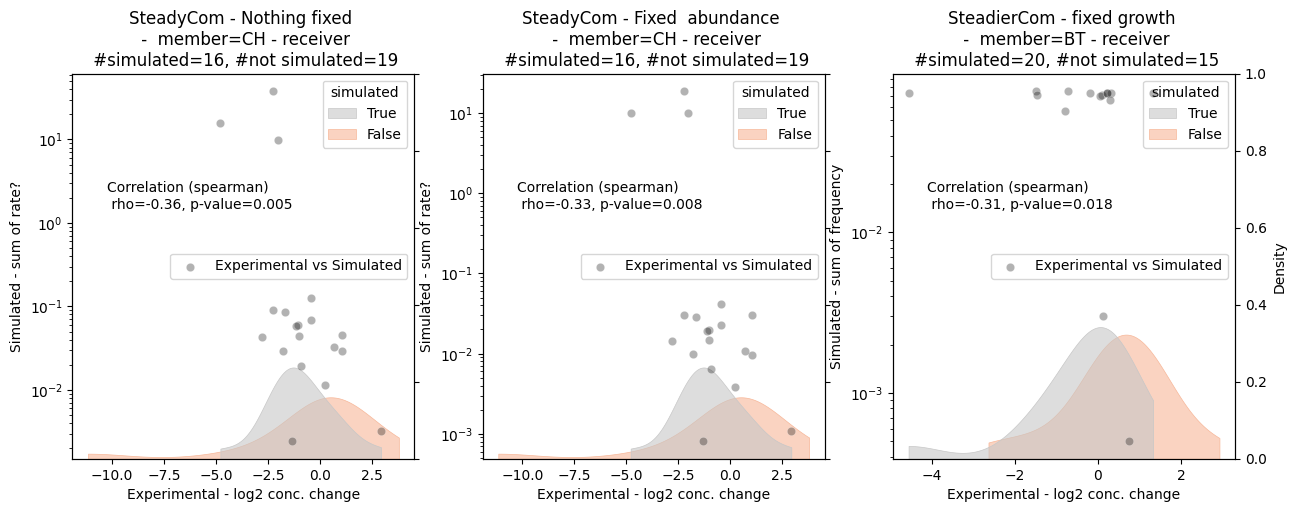

In [61]:
fig,axs,axs_twin = correlation.plot_scatterplots_from_corr(results_corr_member_df_red.head(3),simulation_dict,signal_exp,member_or_met="member")

In [62]:
simulated_res = simulation_dict["receiver"]["steadiercom"]["SteadierCom - fixed growth"]

simulated_res_red = simulated_res[simulated_res.receiver.isin(["BU","BT","CH"])]


INFO     | make_scatterplot removes nan values in 'simulated' column for scatterplot and uses all values for density plot.
INFO     | merge_sim_exp removes compounds not in experimental data
INFO     | find_correlation uses fillna(0) for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data


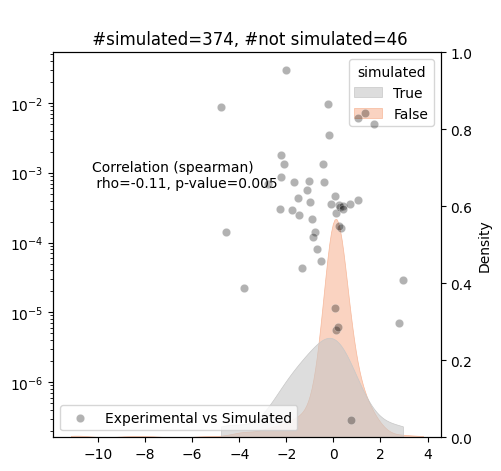

In [63]:
fig,ax,ax_twin = correlation.make_scatterplot(simulated_res_red, signal_exp,receiver_or_donor="receiver",metric="frequency*mass_rate",agg_method="sum", met_column="met_group",ax=None,xlabel="",ylabel="",title="",legend=True,verbose=True)
#ax.set_yscale("linear")

#### Metabolite

In [64]:

results_corr_met_df_red = (results_corr_met_df_bh.query("`p-value` <= 0.05")
                           .xs("donor",drop_level=False)
                           .sort_values("r"))
results_corr_met_df_red.head(5)

r  \
role  simulation_method condition                              agg_method metric              met_group                
donor steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate Alanine pool -0.603269   
                        SteadierCom - fixed growth             sum        frequency           Alanine pool -0.603269   
                                                                          frequency*mass_rate Alanine pool -0.568796   
                        SteadierCom - fixed abundance          sum        frequency*mass_rate Alanine pool -0.534324   
                        SteadierCom - fixed growth & abundance sum        frequency           Alanine pool -0.534324   

                                                                                                             p-value  \
role  simulation_method condition                              agg_method metric              met_group                
donor steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate Alanine pool  0.009940   
                        SteadierCom - fixed growth             sum        frequency           Alanine pool  0.009940   
                                                                          frequency*mass_rate Alanine pool  0.015074   
                        SteadierCom - fixed abundance          sum        frequency*mass_rate Alanine pool  0.022414   
                        SteadierCom - fixed growth & abundance sum        frequency           Alanine pool  0.022414   

                                                                                                            datapoints  \
role  simulation_method condition                              agg_method metric              met_group                  
donor steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate Alanine pool        12.0   
                        SteadierCom - fixed growth             sum        frequency           Alanine pool        12.0   
                                                                          frequency*mass_rate Alanine pool        12.0   
                        SteadierCom - fixed abundance          sum        frequency*mass_rate Alanine pool        12.0   
                        SteadierCom - fixed growth & abundance sum        frequency           Alanine pool        12.0   

                                                                                                            rank  \
role  simulation_method condition                              agg_method metric              met_group            
donor steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate Alanine pool   3.5   
                        SteadierCom - fixed growth             sum        frequency           Alanine pool   3.5   
                                                                          frequency*mass_rate Alanine pool   8.0   
                        SteadierCom - fixed abundance          sum        frequency*mass_rate Alanine pool  16.0   
                        SteadierCom - fixed growth & abundance sum        frequency           Alanine pool  16.0   

                                                                                                            p-value BH critical  \
role  simulation_method condition                              agg_method metric              met_group                           
donor steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate Alanine pool             0.000278   
                        SteadierCom - fixed growth             sum        frequency           Alanine pool             0.000278   
                                                                          frequency*mass_rate Alanine pool             0.000635   
                        SteadierCom - fixed abundance          sum        frequency*mass_rate Alanine pool    

In [65]:

results_corr_met_df_red = (results_corr_met_df_bh.query("`p-value` <= 0.05")
                           .xs("receiver",drop_level=False)
                           .sort_values("r"))
results_corr_met_df_red.head(5)

r  \
role     simulation_method condition                              agg_method metric              met_group                 
receiver steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate Serine pool   -0.638978   
                           SteadierCom - fixed growth             sum        frequency*mass_rate Arginine pool -0.637741   
         steadycom         SteadyCom - Nothing fixed              sum        rate?               Serine pool   -0.599042   
         steadiercom       SteadierCom - fixed growth             sum        frequency           Serine pool   -0.599042   
                           SteadierCom - fixed abundance          sum        frequency*mass_rate Serine pool   -0.599042   

                                                                                                                 p-value  \
role     simulation_method condition                              agg_method metric              met_group                 
receiver steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate Serine pool    0.008381   
                           SteadierCom - fixed growth             sum        frequency*mass_rate Arginine pool  0.006426   
         steadycom         SteadyCom - Nothing fixed              sum        rate?               Serine pool    0.013453   
         steadiercom       SteadierCom - fixed growth             sum        frequency           Serine pool    0.013453   
                           SteadierCom - fixed abundance          sum        frequency*mass_rate Serine pool    0.013453   

                                                                                                                datapoints  \
role     simulation_method condition                              agg_method metric              met_group                   
receiver steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate Serine pool          12.0   
                           SteadierCom - fixed growth             sum        frequency*mass_rate Arginine pool        12.0   
         steadycom         SteadyCom - Nothing fixed              sum        rate?               Serine pool          12.0   
         steadiercom       SteadierCom - fixed growth             sum        frequency           Serine pool          12.0   
                           SteadierCom - fixed abundance          sum        frequency*mass_rate Serine pool          12.0   

                                                                                                                rank  \
role     simulation_method condition                              agg_method metric              met_group             
receiver steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate Serine pool     2.0   
                           SteadierCom - fixed growth             sum        frequency*mass_rate Arginine pool   1.0   
         steadycom         SteadyCom - Nothing fixed              sum        rate?               Serine pool     6.0   
         steadiercom       SteadierCom - fixed growth             sum        frequency           Serine pool     6.0   
                           SteadierCom - fixed abundance          sum        frequency*mass_rate Serine pool     6.0   

                                                                                                                p-value BH critical  \
role     simulation_method condition                              agg_method metric              met_group                            
receiver steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate Serine pool               0.000159   
                           SteadierCom - fixed growth             sum        frequency*mass_rate Arginine pool             0.000079   
         steadycom         SteadyCom - Nothing fixed              sum        rate?               Serine pool         

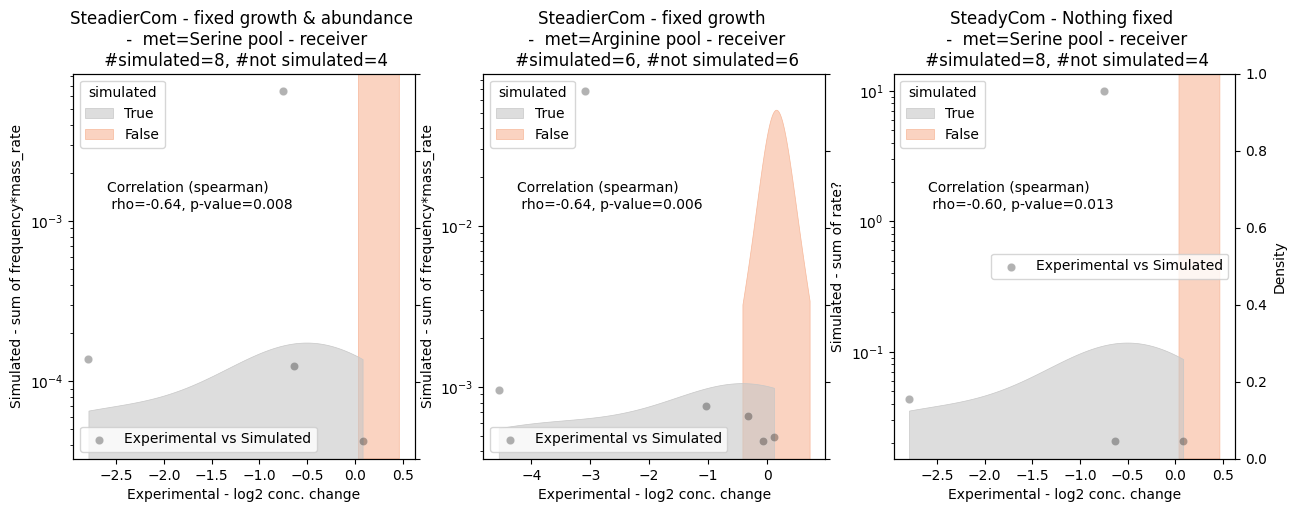

In [66]:
fig,axs,axs_twin = correlation.plot_scatterplots_from_corr(results_corr_met_df_red.head(3),simulation_dict,signal_exp,member_or_met="met")

###  SteadierCom results - frequency

INFO     | make_scatterplot removes nan values in 'simulated' column for scatterplot and uses all values for density plot.
INFO     | merge_sim_exp removes compounds not in experimental data
INFO     | find_correlation uses fillna(0) for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data
INFO     | make_scatterplot removes nan values in 'simulated' column for scatterplot and uses all values for density plot.
INFO     | merge_sim_exp removes compounds not in experimental data
INFO     | find_correlation uses fillna(0) for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data


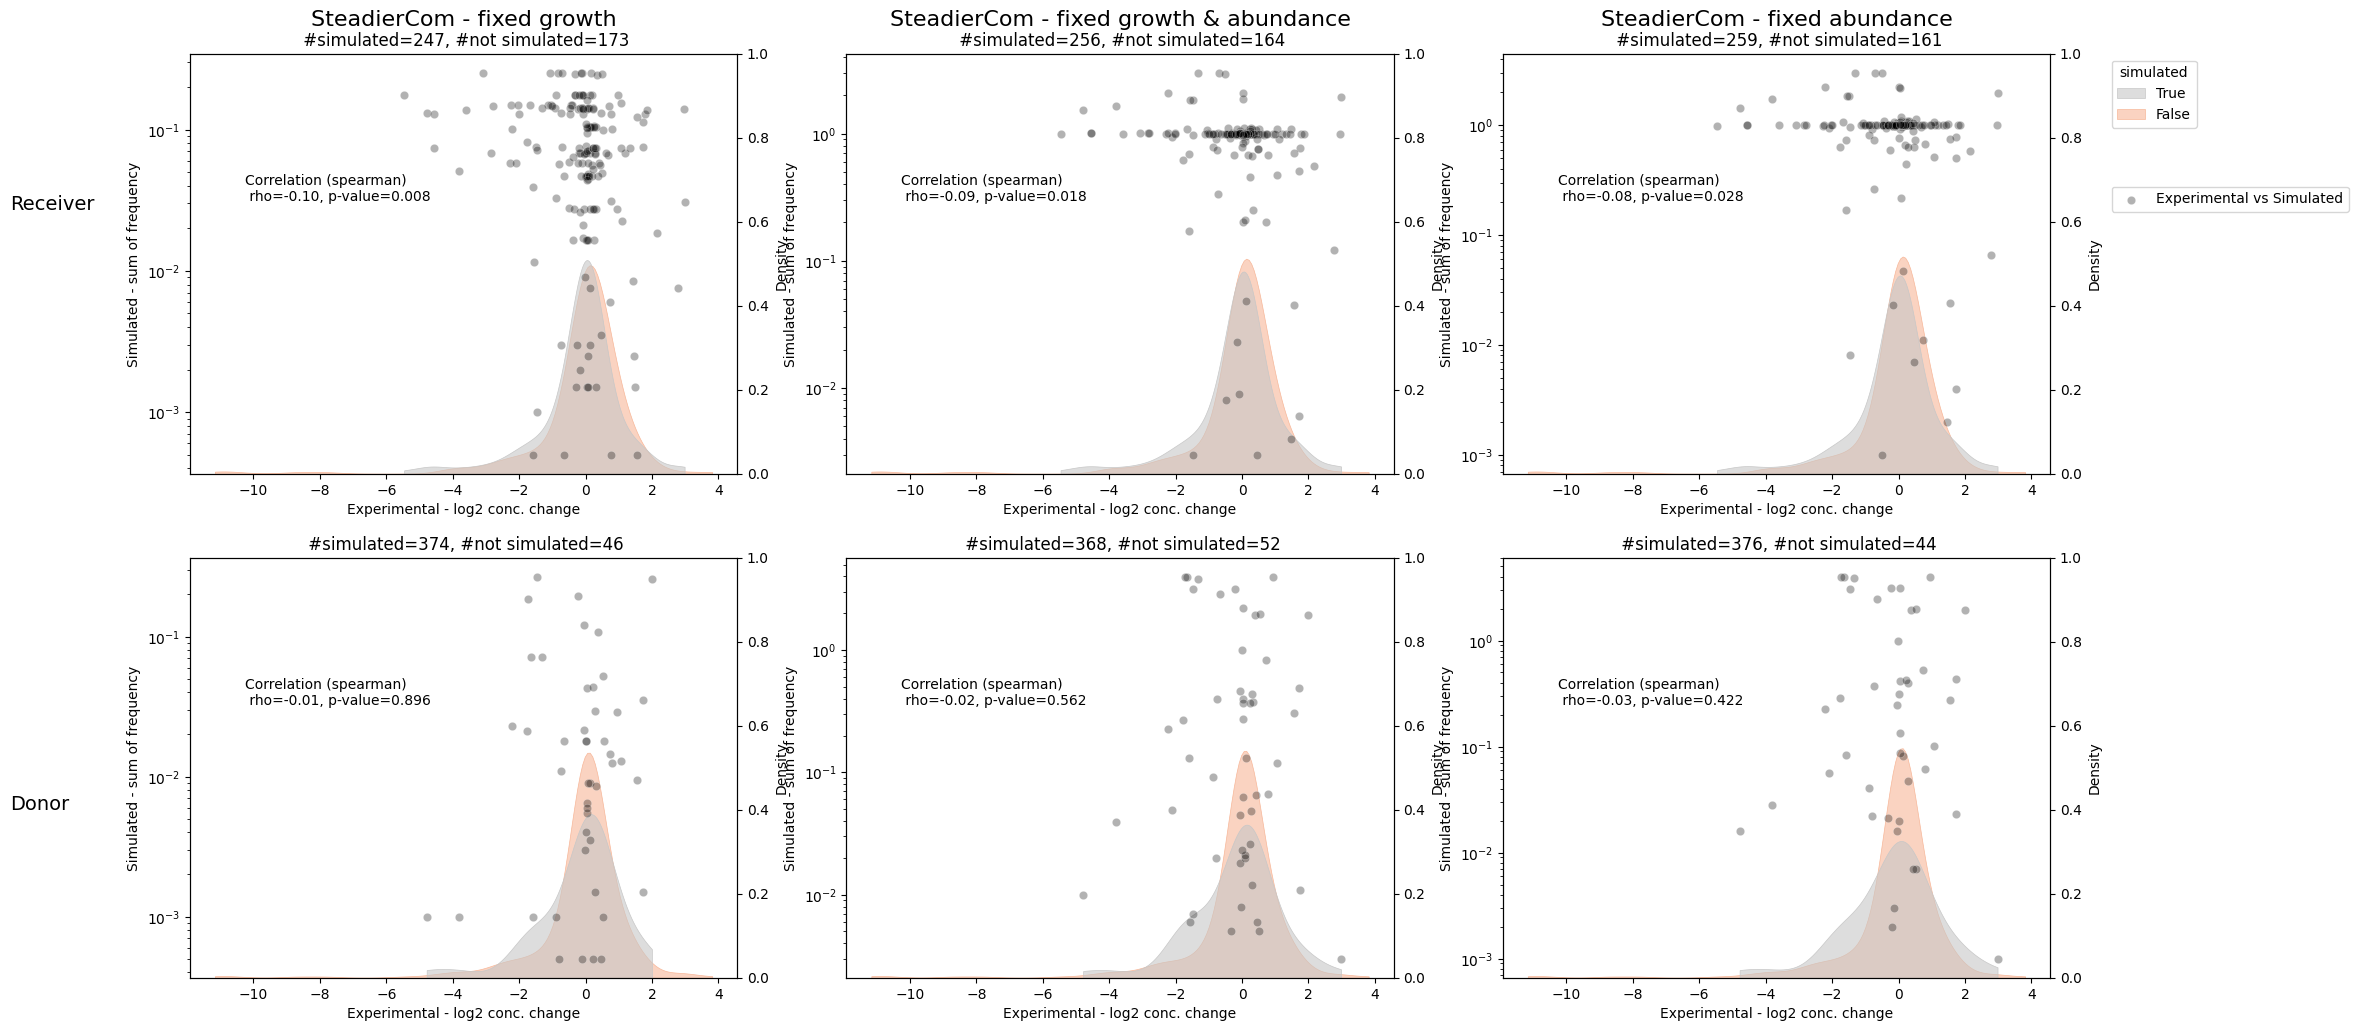

In [67]:
fig, axs, twin_axes = correlation.make_scatterplots_simulation_method(simulation_dict, 
                                                signal_exp,
                                                simulation_method="steadiercom",
                                                metric="frequency",
                                                )

INFO     | make_scatterplot removes nan values in 'simulated' column for scatterplot and uses all values for density plot.
INFO     | merge_sim_exp removes compounds not in experimental data
INFO     | find_correlation uses fillna(0) for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data
INFO     | make_scatterplot removes nan values in 'simulated' column for scatterplot and uses all values for density plot.
INFO     | merge_sim_exp removes compounds not in experimental data
INFO     | find_correlation uses fillna(0) for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data


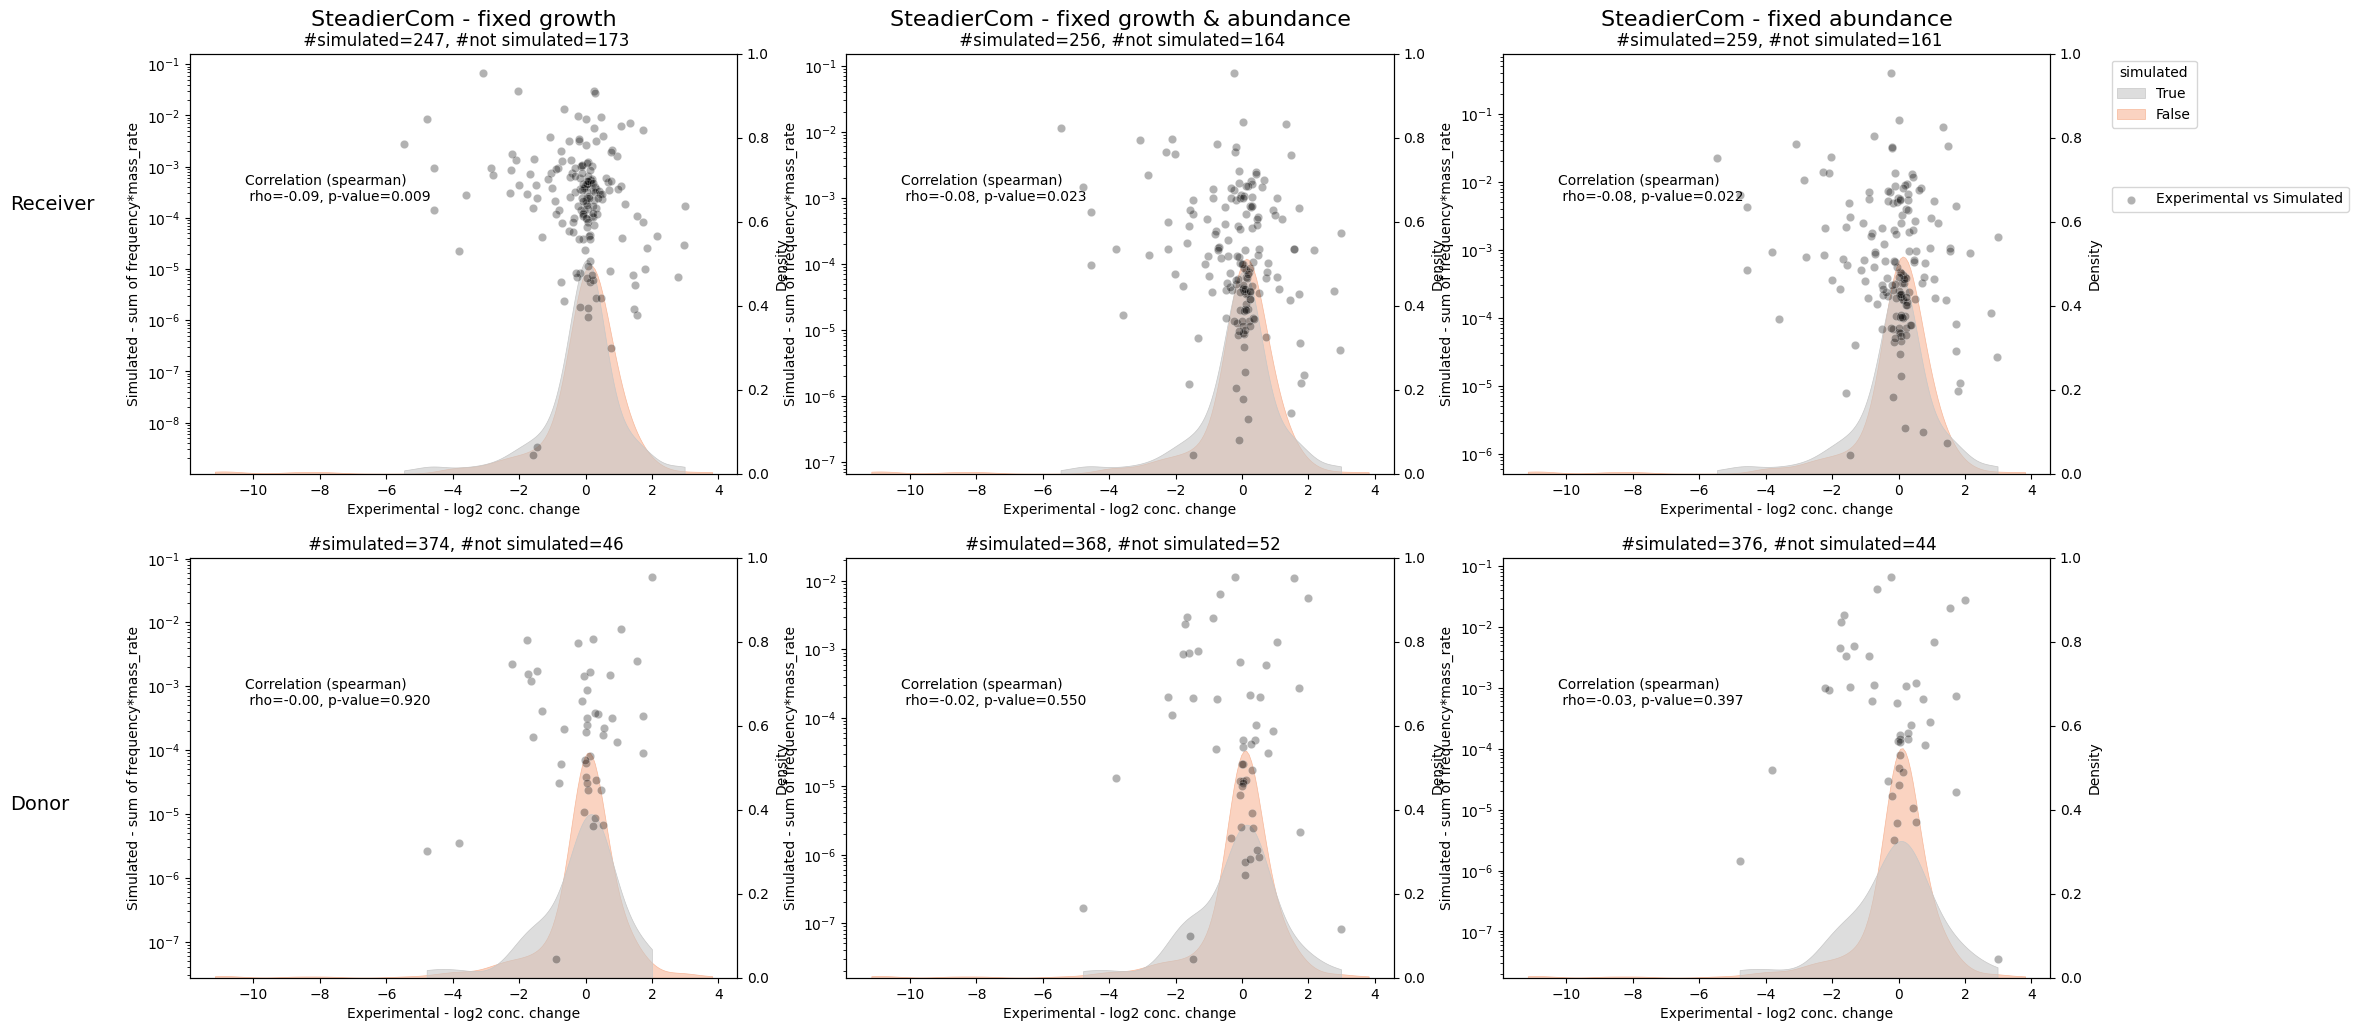

In [68]:
fig, axs, twin_axes = correlation.make_scatterplots_simulation_method(simulation_dict, 
                                                signal_exp,
                                                simulation_method="steadiercom",
                                                metric="frequency*mass_rate",
                                                )


# Diagnostic analysis - Binary data

In [69]:
support_df = diagnostic.identify_support(signal_exp)
support_df.sort_index(ascending=False)

,,positive_support,negative_support,total,no-skill line
receiver,1,60,360,420,0.142857
donor,1,40,380,420,0.095238


## Precision-Recall curves

In [70]:
results_pr_auc_df = diagnostic.find_pvalues_of_PR(simulation_dict,signal_exp)

INFO     | merge_sim_exp removes compounds not in experimental data


In [71]:

results_pr_auc_df_bh = results_pr_auc_df.copy()
results_pr_auc_df_bh["rank"] = results_pr_auc_df_bh["p_value"].rank()
results_pr_auc_df_bh["p-value BH critical"] = (results_pr_auc_df_bh["rank"]/results_pr_auc_df_bh.shape[0])*0.05
results_pr_auc_df_bh["pass BH test"] = results_pr_auc_df_bh["p_value"]<results_pr_auc_df_bh["p-value BH critical"]

### Best predictor of receiver-metabolite relationships

In [72]:
mask_best = ((results_pr_auc_df_bh.p_value<0.05) & (results_pr_auc_df_bh.index.get_level_values("role")=="receiver"))

best_pr_predictors = results_pr_auc_df_bh[mask_best].sort_values(by="p_value")
best_pr_predictors


p_value  \
role     simulation_method condition                              agg_method metric              exp_thresh            
receiver steadiercom       SteadierCom - fixed growth & abundance sum        frequency           1            0.0020   
                           SteadierCom - fixed abundance          sum        frequency           1            0.0041   
         steadycom         SteadyCom - Fixed  abundance           sum        rate?               1            0.0119   
         steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate 1            0.0122   
                           SteadierCom - fixed growth & abundance sum        frequency*mass_rate 1            0.0219   
         steadycom         SteadyCom - Nothing fixed              sum        rate?               1            0.0246   
         steadiercom       SteadierCom - fixed growth             sum        frequency           1            0.0254   
                           SteadierCom - fixed abundance          sum        frequency*mass_rate 1            0.0425   

                                                                                                             observed_auc  \
role     simulation_method condition                              agg_method metric              exp_thresh                 
receiver steadiercom       SteadierCom - fixed growth & abundance sum        frequency           1               0.228740   
                           SteadierCom - fixed abundance          sum        frequency           1               0.215555   
         steadycom         SteadyCom - Fixed  abundance           sum        rate?               1               0.205691   
         steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate 1               0.208304   
                           SteadierCom - fixed growth & abundance sum        frequency*mass_rate 1               0.199243   
         steadycom         SteadyCom - Nothing fixed              sum        rate?               1               0.193691   
         steadiercom       SteadierCom - fixed growth             sum        frequency           1               0.195000   
                           SteadierCom - fixed abundance          sum        frequency*mass_rate 1               0.189904   

                                                                                                             rank  \
role     simulation_method condition                              agg_method metric              exp_thresh         
receiver steadiercom       SteadierCom - fixed growth & abundance sum        frequency           1            1.0   
                           SteadierCom - fixed abundance          sum        frequency           1            2.0   
         steadycom         SteadyCom - Fixed  abundance           sum        rate?               1            4.0   
         steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate 1            5.0   
                           SteadierCom - fixed growth & abundance sum        frequency*mass_rate 1            6.0   
         steadycom         SteadyCom - Nothing fixed              sum        rate?               1            7.0   
         steadiercom       SteadierCom - fixed growth             sum        frequency           1            8.0   
                           SteadierCom - fixed abundance          sum        frequency*mass_rate 1            9.0   

                                                                                                             p-value BH critical  \
role     simulation_method condition                              agg_method metric              exp_thresh                        
receiver steadiercom       SteadierCom - fixed growth & abundance sum        frequency           1                      0.002778   
                           SteadierCom - fixed abundance          sum        frequency    

INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data
/var/folders/mc/1rm74nkd4s78l46281nyt5wm0000gn/T/ipykernel_57114/2144134324.py:5: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
/var/folders/mc/1rm74nkd4s78l46281nyt5wm0000gn/T/ipykernel_57114/2144134324.py:5: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  fig.tight_layout()


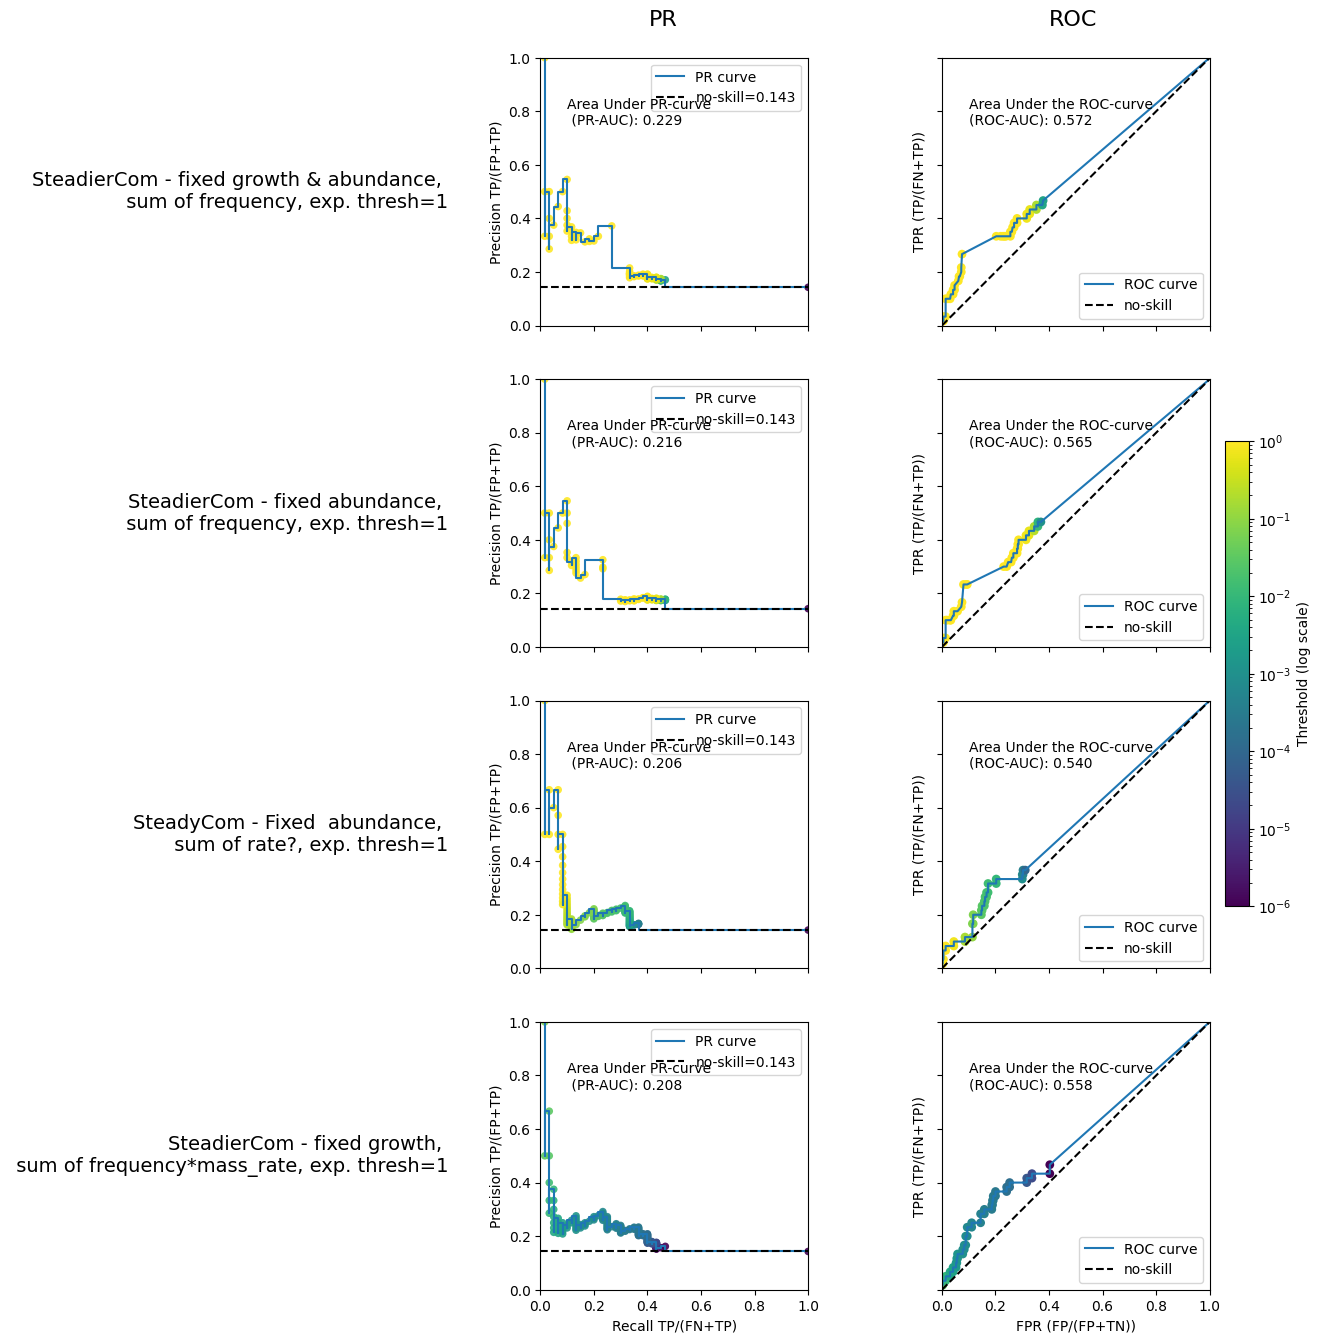

In [73]:
fig, axs = diagnostic.plot_diagnostic_curves_pvalues(best_pr_predictors.head(4),
                                                  simulation_dict,
                                                  signal_exp,
                                                  receiver_or_donor="receiver")
fig.tight_layout()

### Best predictor of donor-metabolite relationships

In [74]:
mask_best = ((results_pr_auc_df_bh.p_value<0.05) & (results_pr_auc_df_bh.index.get_level_values("role")=="donor"))

best_pr_predictors = results_pr_auc_df_bh[mask_best].sort_values(by="p_value")
best_pr_predictors


,,,,,,p_value,observed_auc,rank,p-value BH critical,pass BH test
role,simulation_method,condition,agg_method,metric,exp_thresh,,,,,
donor,steadiercom,SteadierCom - fixed growth,sum,frequency*mass_rate,1,0.01,0.155407,3.0,0.008333,False


INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data


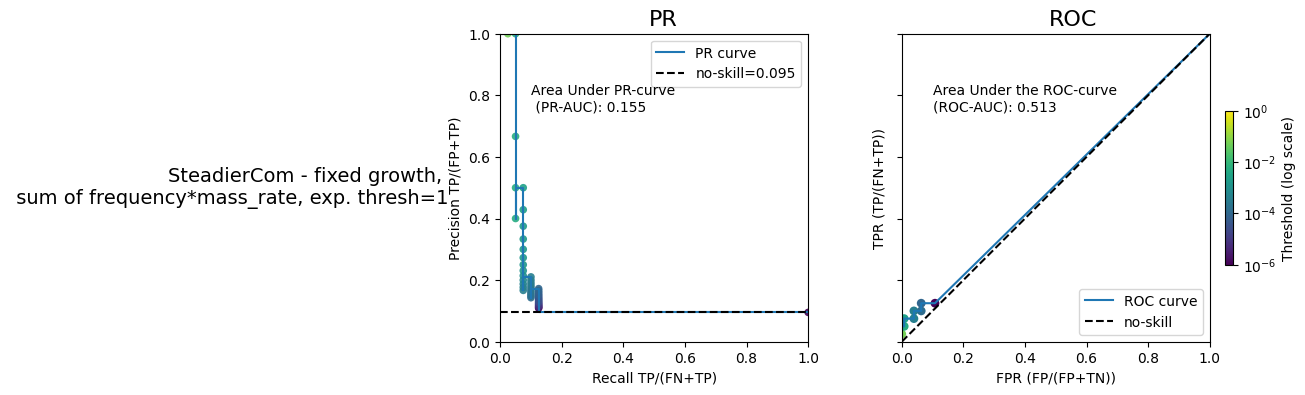

In [75]:
fig, axs = diagnostic.plot_diagnostic_curves_pvalues(best_pr_predictors.head(3),
                                                  simulation_dict,
                                                  signal_exp,
                                                  receiver_or_donor="donor")

INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data


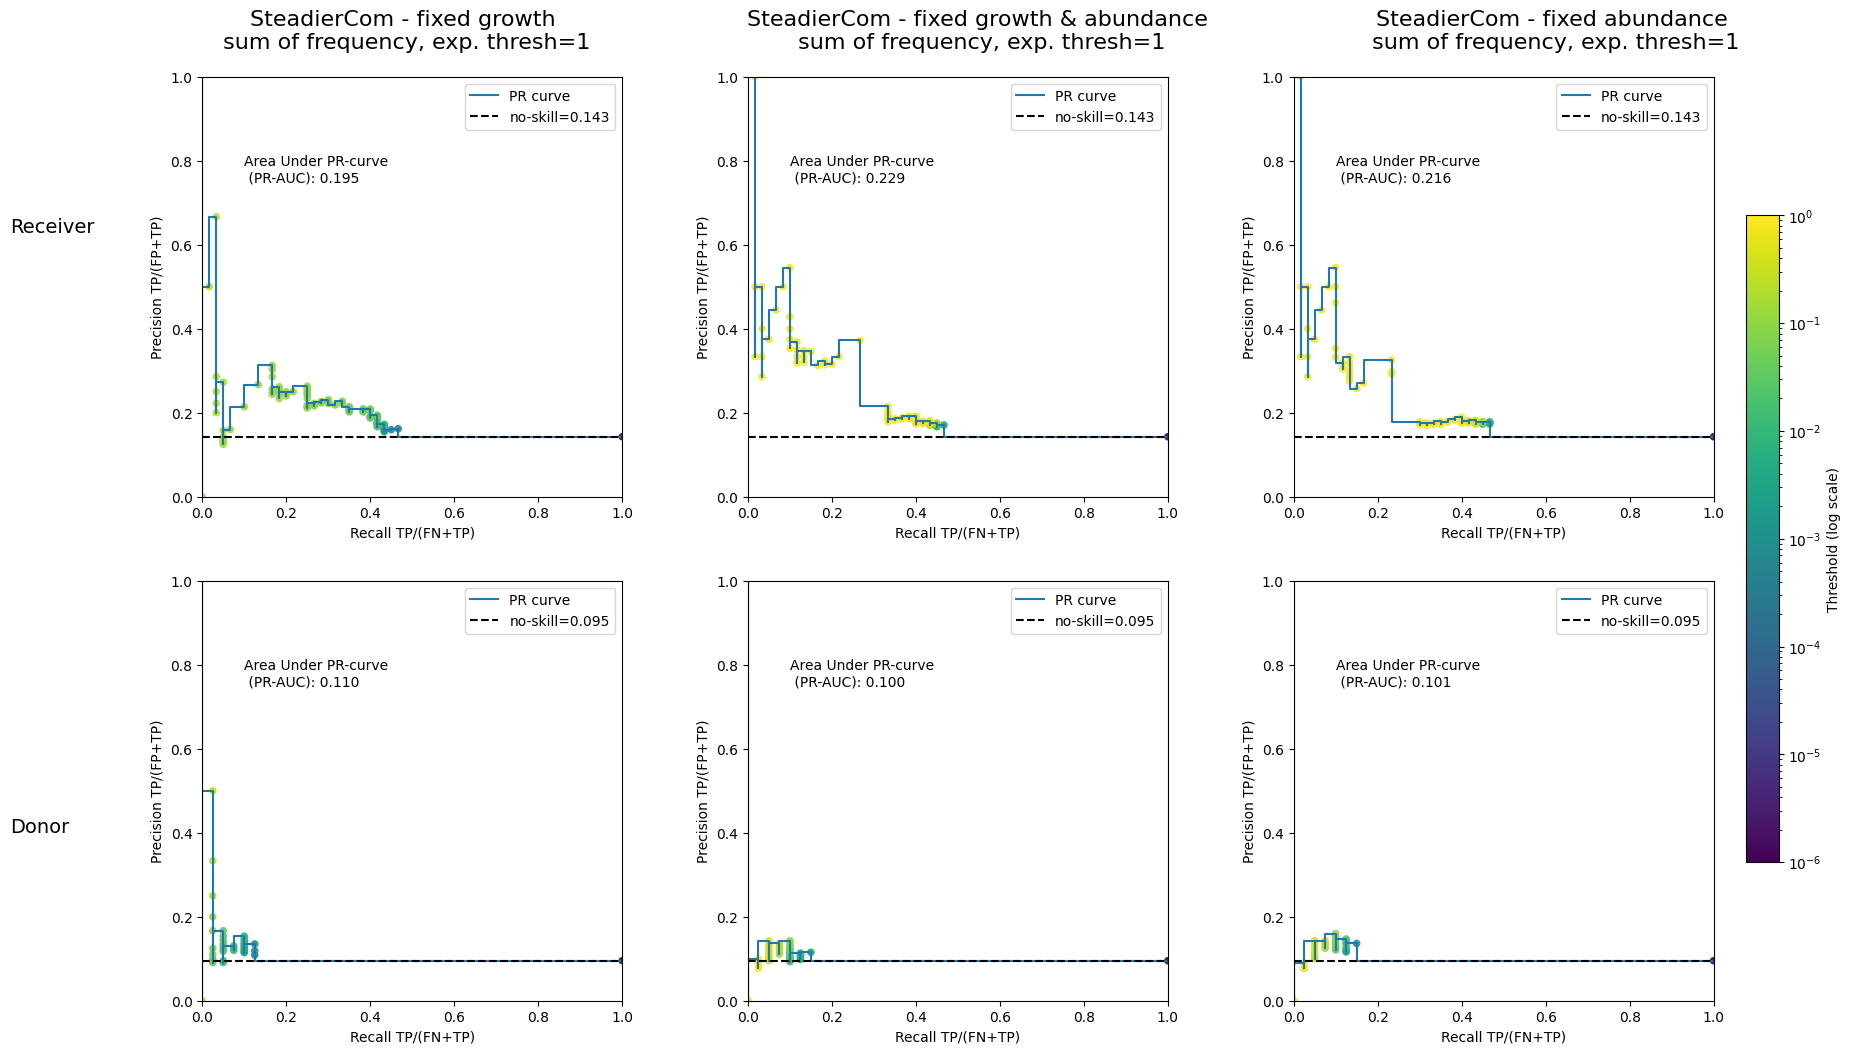

In [76]:
fig,axs = diagnostic.plot_diagnostic_curves_method(simulation_dict,
                                                    signal_exp,
                                                    simulation_method="steadiercom",
                                                    metric="frequency",
                                                    met_column="met_group",
                                                    agg_method="sum")

INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data


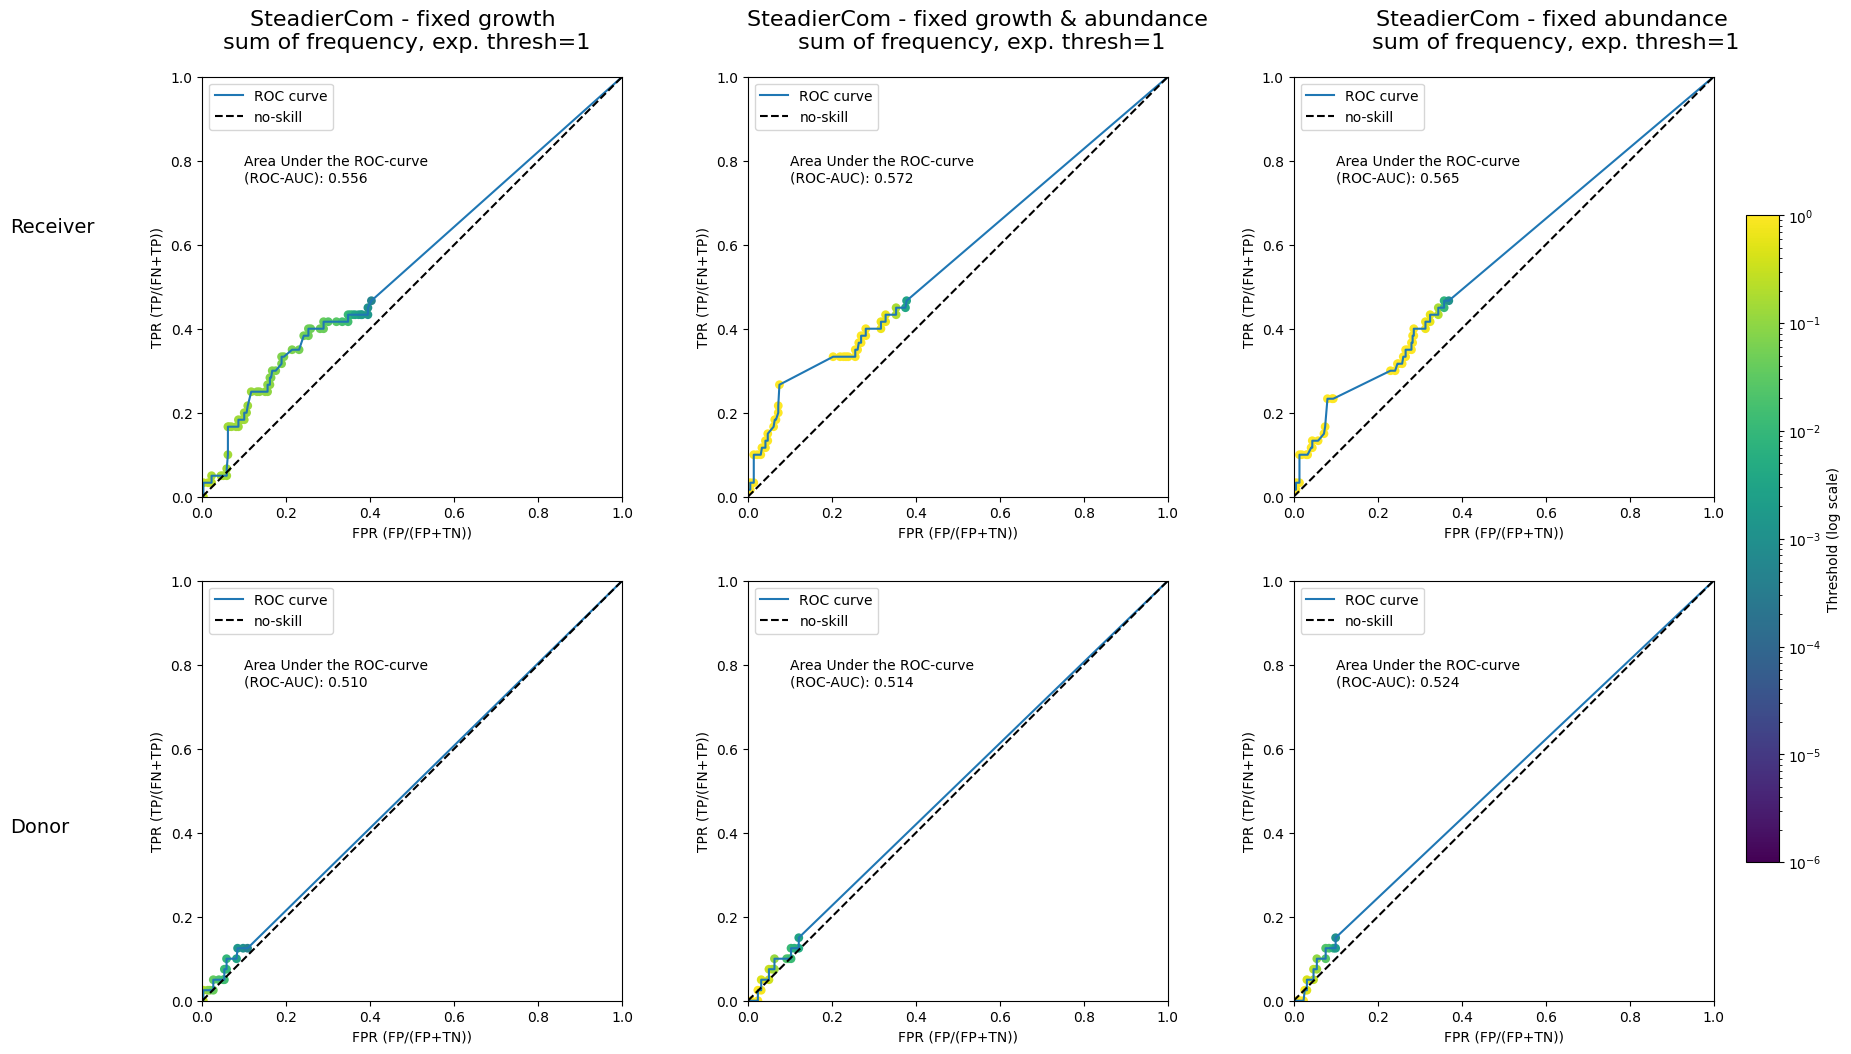

In [77]:
fig,axs = diagnostic.plot_diagnostic_curves_method(simulation_dict,
                                                    signal_exp,
                                                    simulation_method="steadiercom",
                                                    PR_or_ROC="ROC",
                                                    metric="frequency",
                                                    met_column="met_group",
                                                    agg_method="sum")

INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data


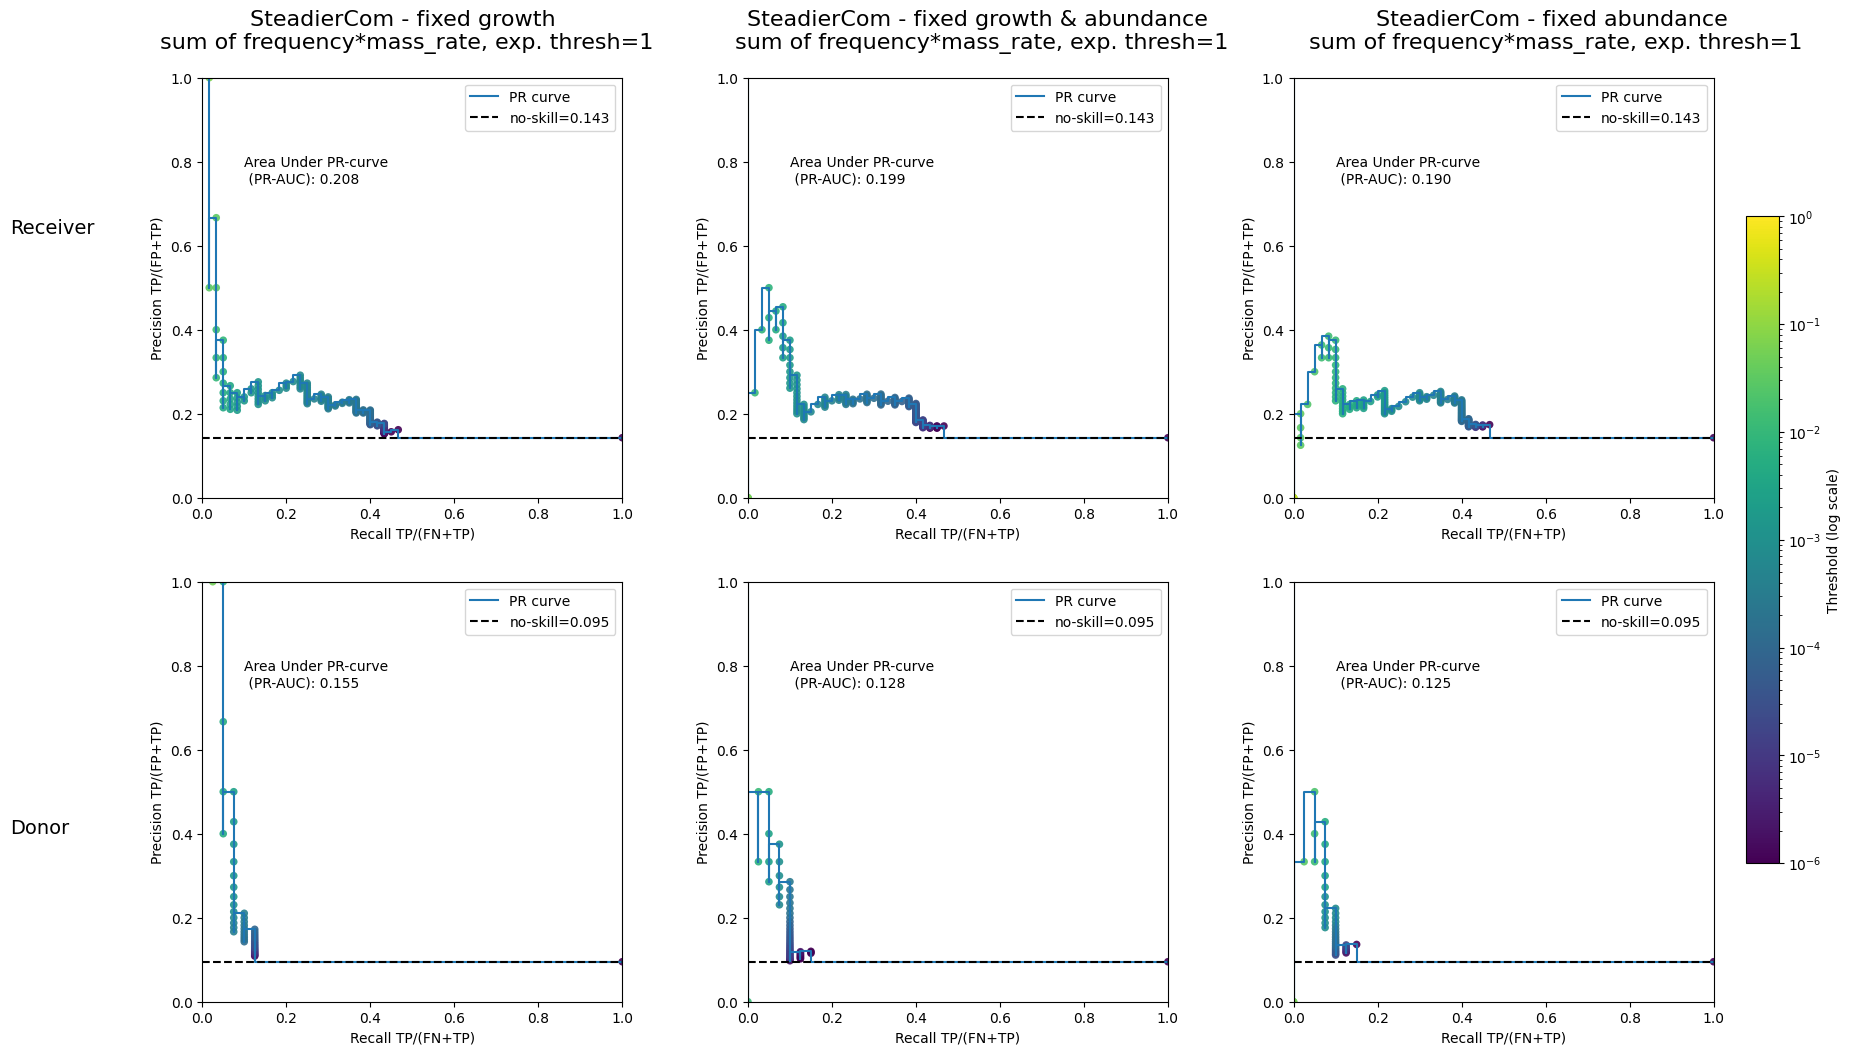

In [78]:
fig,axs = diagnostic.plot_diagnostic_curves_method(simulation_dict,
                                                    signal_exp,
                                                    simulation_method="steadiercom",
                                                    metric="frequency*mass_rate",
                                                    met_column="met_group",
                                                    agg_method="sum")

INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data


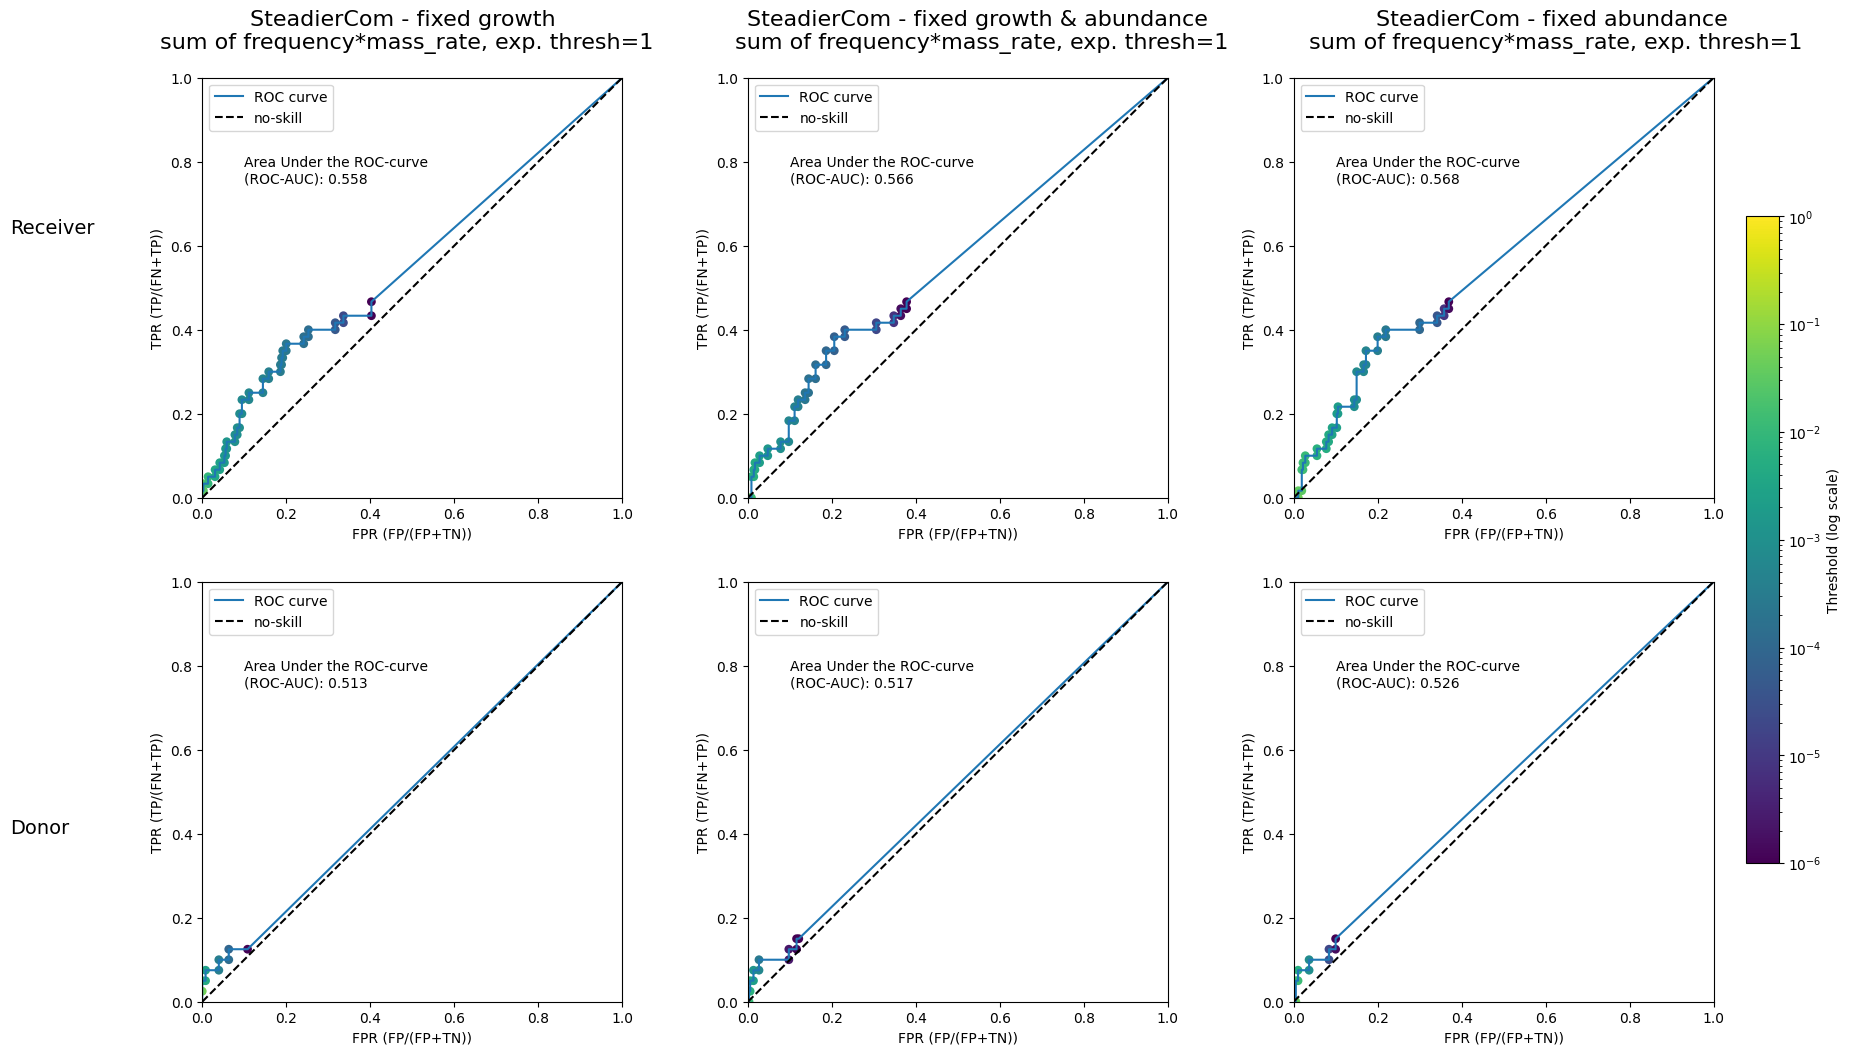

In [79]:
fig,axs = diagnostic.plot_diagnostic_curves_method(simulation_dict,
                                                    signal_exp,
                                                    simulation_method="steadiercom",
                                                    metric="frequency*mass_rate",
                                                    PR_or_ROC="ROC",
                                                    met_column="met_group",
                                                    agg_method="sum")

INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data


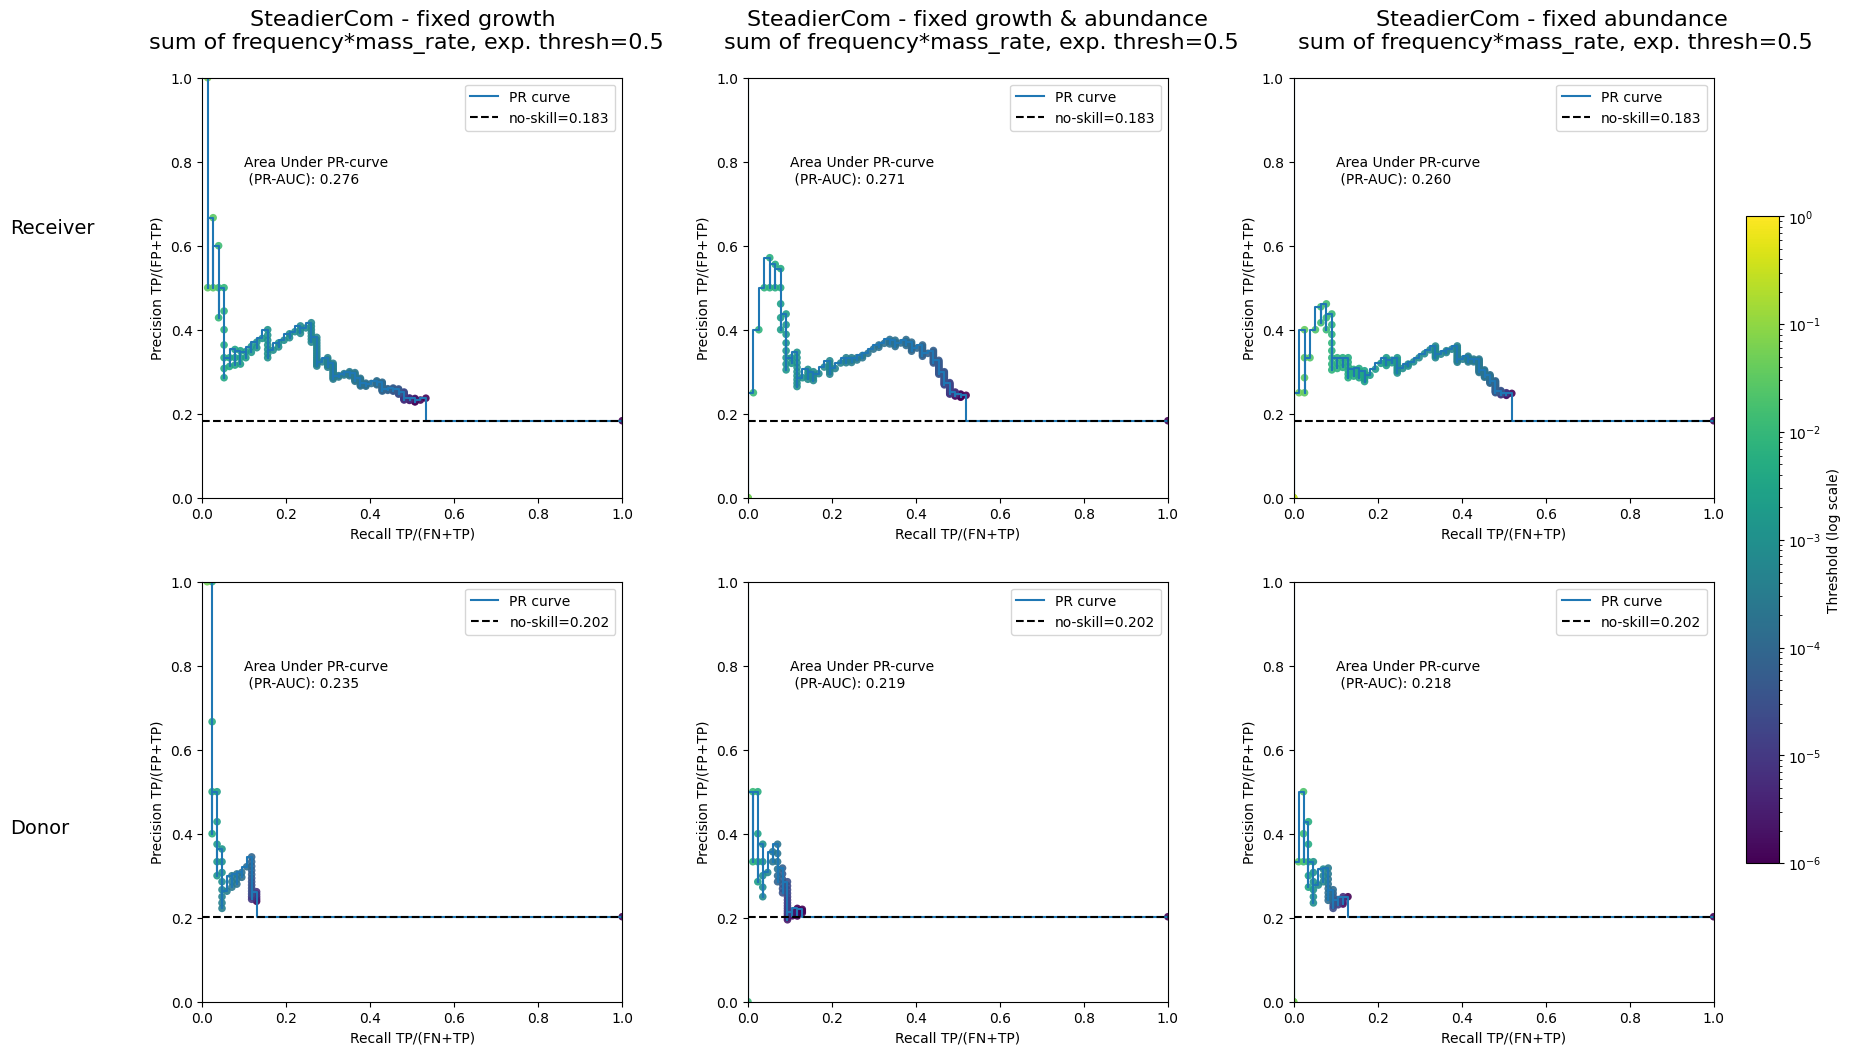

In [80]:
fig,axs = diagnostic.plot_diagnostic_curves_method(simulation_dict,
                                                    signal_exp,
                                                    simulation_method="steadiercom",
                                                    metric="frequency*mass_rate",
                                                    met_column="met_group",
                                                    exp_thresh=0.5,
                                                    agg_method="sum")